# Q9 — Genetic Algorithm for the Travelling Salesman Problem

This notebook uses a genetic algorithm to find a short round-trip visiting eight cities once. A chromosome is a city order; the first city is not fixed, and the final edge returns to the start. The algorithm uses tournament selection, order crossover, swap mutation and elitism.

## 1. City coordinates and distance matrix

Euclidean distance is used between each pair of cities. The route length includes the return from the last city to the first.

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
cities = np.array([[0,0],[2,6],[5,3],[6,8],[8,2],[9,6],[3,9],[1,4]], dtype=float)
n = len(cities)
distance = np.linalg.norm(cities[:, None, :] - cities[None, :, :], axis=2)

def tour_length(route):
    return sum(distance[route[i], route[(i+1) % len(route)]] for i in range(len(route)))

print(f"Cities: {n}; distance matrix shape: {distance.shape}")
print("Example A -> B distance:", round(distance[0,1], 3))

Cities: 8; distance matrix shape: (8, 8)
Example A -> B distance: 6.325

## 2. GA operators

Tournament selection picks the best of four sampled candidates. Order crossover copies a segment from one parent and fills remaining positions in the order found in the other parent. Swap mutation exchanges two cities; elitism carries the current best route into the next generation.

In [1]:
def tournament_selection(population, scores, k=4):
    choices = random.sample(range(len(population)), k)
    winner = min(choices, key=lambda i: scores[i])
    return population[winner][:]

def order_crossover(parent1, parent2):
    left, right = sorted(random.sample(range(n), 2))
    child = [None] * n
    child[left:right+1] = parent1[left:right+1]
    fill = [city for city in parent2 if city not in child]
    positions = list(range(right+1, n)) + list(range(0, left))
    for pos, city in zip(positions, fill):
        child[pos] = city
    return child

def swap_mutation(route):
    route = route[:]
    i, j = random.sample(range(n), 2)
    route[i], route[j] = route[j], route[i]
    return route

print("Selection: tournament (k=4)")
print("Crossover: order crossover")
print("Mutation: swap two city positions")
print("Elitism: retain one best individual")

Selection: tournament (k=4)
Crossover: order crossover
Mutation: swap two city positions
Elitism: retain one best individual

## 3. Run the genetic algorithm

The run uses a population of 60 tours for 100 generations. The fixed seed makes the run reproducible. The reported route is a good solution found by this run, not a proof that no shorter tour exists.

In [1]:
population_size, generations = 60, 100
crossover_rate, mutation_rate = 0.90, 0.15
population = [random.sample(range(n), n) for _ in range(population_size)]
best_history = []
checkpoints = {}

for generation in range(generations + 1):
    scores = [tour_length(route) for route in population]
    best_idx = int(np.argmin(scores))
    best_history.append(scores[best_idx])
    if generation in [0,10,20,30,40,50,60,70,80,90,100]:
        checkpoints[generation] = scores[best_idx]
    if generation == generations:
        break
    next_population = [population[best_idx][:]]  # elitism
    while len(next_population) < population_size:
        p1 = tournament_selection(population, scores)
        p2 = tournament_selection(population, scores)
        child = order_crossover(p1, p2) if random.random() < crossover_rate else p1[:]
        if random.random() < mutation_rate:
            child = swap_mutation(child)
        next_population.append(child)
    population = next_population

scores = [tour_length(route) for route in population]
best_route = population[int(np.argmin(scores))]
print(f"Population: {population_size} | Generations: {generations} | Crossover: {crossover_rate:.2f} | Mutation: {mutation_rate:.2f}")
print(f"Initial best distance: {best_history[0]:.3f}")
for g in range(10, generations+1, 10):
    print(f"Gen {g:3d}: {best_history[g]:.3f}")
print("Best route:", " -> ".join(chr(65+i) for i in best_route + [best_route[0]]))
print(f"Best tour distance: {tour_length(best_route):.4f}")

Cities: A, B, C, D, E, F, G, H
Population: 60 | Generations: 100 | Crossover: 0.90 | Mutation: 0.15
Initial best distance: 36.258
Gen  10: 29.406
Gen  20: 29.406
Gen  30: 29.406
Gen  40: 29.406
Gen  50: 29.406
Gen  60: 29.406
Gen  70: 29.406
Gen  80: 29.406
Gen  90: 29.406
Gen 100: 29.406
Best route: B -> H -> A -> C -> E -> F -> D -> G -> B
Best tour distance: 29.4056

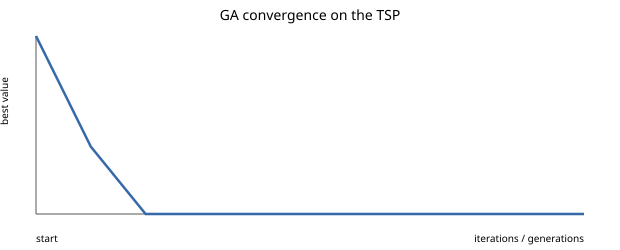

In [1]:
plt.figure(figsize=(8,4))
plt.plot(best_history)
plt.xlabel('Generation')
plt.ylabel('Best tour distance')
plt.title('GA convergence on the TSP')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Result and interpretation

The best tour distance decreases from the initial population's best value to about **29.4056**. The curve levels off early in this seeded run, so additional generations or a larger population may not improve this particular run. GA is stochastic; results can change with the seed, city layout and operator settings.